In [17]:
import os, math, random
import numpy as np, pandas as pd, cv2, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED=42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
PROJECT_ROOT=os.path.abspath("..")  # notebook is in notebooks/
DATA_PROCESSED=os.path.join(PROJECT_ROOT,"data","processed")
MODEL_DIR=os.path.join(PROJECT_ROOT,"models")
EXPERIMENT_DIR=os.path.join(PROJECT_ROOT,"experiments","training")
os.makedirs(MODEL_DIR,exist_ok=True); os.makedirs(EXPERIMENT_DIR,exist_ok=True)
IMG_HEIGHT,IMG_WIDTH=66,200
BATCH_SIZE=64
EPOCHS=40
CAMERA_STEERING_CORRECTION=0.20
print("TensorFlow:",tf.__version__,"GPUs:",tf.config.list_physical_devices("GPU"))
print("Project root:",PROJECT_ROOT)

TensorFlow: 2.21.0 GPUs: []
Project root: C:\Users\user\Neuro Drive


In [28]:
train_df = pd.read_csv(
    os.path.join(DATA_PROCESSED, "train_manifest.csv")
)

val_df = pd.read_csv(
    os.path.join(DATA_PROCESSED, "validation_manifest.csv")
)

print("Train rows:", len(train_df))
print("Validation rows:", len(val_df))

display(train_df.head())
display(val_df.head())

assert len(train_df) > 0 and len(val_df) > 0
assert {"center", "steering", "throttle"}.issubset(val_df.columns)

Train rows: 1661
Validation rows: 356


,center,left,right,steering,throttle,sampling_weight
0,C:\Users\user\Neuro Drive\data\raw\IMG\center_...,C:\Users\user\Neuro Drive\data\raw\IMG\left_20...,C:\Users\user\Neuro Drive\data\raw\IMG\right_2...,0.05,0.0,1.795676
1,C:\Users\user\Neuro Drive\data\raw\IMG\center_...,C:\Users\user\Neuro Drive\data\raw\IMG\left_20...,C:\Users\user\Neuro Drive\data\raw\IMG\right_2...,0.00,0.0,0.065265
2,C:\Users\user\Neuro Drive\data\raw\IMG\center_...,C:\Users\user\Neuro Drive\data\raw\IMG\left_20...,C:\Users\user\Neuro Drive\data\raw\IMG\right_2...,0.00,0.0,0.065265
3,C:\Users\user\Neuro Drive\data\raw\IMG\center_...,C:\Users\user\Neuro Drive\data\raw\IMG\left_20...,C:\Users\user\Neuro Drive\data\raw\IMG\right_2...,0.00,0.0,0.065265
4,C:\Users\user\Neuro Drive\data\raw\IMG\center_...,C:\Users\user\Neuro Drive\data\raw\IMG\left_20...,C:\Users\user\Neuro Drive\data\raw\IMG\right_2...,1.00,0.0,0.790952


,center,left,right,steering,throttle
0,C:\Users\user\Neuro Drive\data\raw\IMG\center_...,C:\Users\user\Neuro Drive\data\raw\IMG\left_20...,C:\Users\user\Neuro Drive\data\raw\IMG\right_2...,0.00,0.476525
1,C:\Users\user\Neuro Drive\data\raw\IMG\center_...,C:\Users\user\Neuro Drive\data\raw\IMG\left_20...,C:\Users\user\Neuro Drive\data\raw\IMG\right_2...,0.00,0.000000
2,C:\Users\user\Neuro Drive\data\raw\IMG\center_...,C:\Users\user\Neuro Drive\data\raw\IMG\left_20...,C:\Users\user\Neuro Drive\data\raw\IMG\right_2...,0.00,0.000000
3,C:\Users\user\Neuro Drive\data\raw\IMG\center_...,C:\Users\user\Neuro Drive\data\raw\IMG\left_20...,C:\Users\user\Neuro Drive\data\raw\IMG\right_2...,0.75,0.000000
4,C:\Users\user\Neuro Drive\data\raw\IMG\center_...,C:\Users\user\Neuro Drive\data\raw\IMG\left_20...,C:\Users\user\Neuro Drive\data\raw\IMG\right_2...,0.00,0.000000


In [29]:
def preprocess_image(image):
    h,w=image.shape[:2]
    image=image[int(h*.35):h-int(h*.10),:]
    image=cv2.resize(image,(IMG_WIDTH,IMG_HEIGHT),interpolation=cv2.INTER_AREA)
    return cv2.cvtColor(image,cv2.COLOR_BGR2RGB)

def augment_brightness(image):
    factor=np.random.uniform(.65,1.35)
    return np.clip(image.astype(np.float32)*factor,0,255).astype(np.uint8)

def augment_flip(image,steering):
    if np.random.rand()<.5:
        image=cv2.flip(image,1); steering=-steering
    return image,steering

def load_training_sample(row, training=True):

    steering = float(row["steering"])
    throttle = float(row["throttle"])

    if training:
        camera = np.random.choice(["center", "left", "right"])
        path = str(row[camera])

        if camera == "left":
            steering += CAMERA_STEERING_CORRECTION
        elif camera == "right":
            steering -= CAMERA_STEERING_CORRECTION
    else:
        path = str(row["center"])

    image = cv2.imread(path)

    if image is None:
        raise FileNotFoundError(path)

    image = preprocess_image(image)

    if training:
        image = augment_brightness(image)
        image, steering = augment_flip(image, steering)

    return image, np.float32(steering), np.float32(throttle)

In [31]:
class DrivingSequence(keras.utils.Sequence):

    def __init__(self, dataframe, batch_size=64,
                 shuffle=True, training=True, **kwargs):

        super().__init__(**kwargs)

        self.df = dataframe.reset_index(drop=True).copy()
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.training = training

        self.indices = np.arange(len(self.df))
        self.on_epoch_end()

    def __len__(self):
        return math.ceil(len(self.indices) / self.batch_size)

    def __getitem__(self, batch_index):

        ids = self.indices[
            batch_index * self.batch_size:
            (batch_index + 1) * self.batch_size
        ]

        samples = [
            load_training_sample(
                self.df.iloc[i],
                training=self.training
            )
            for i in ids
        ]

        images, angles, throttles = zip(*samples)

        return (
            np.asarray(images, dtype=np.uint8),
            {
                "steering": np.asarray(angles, dtype=np.float32),
                "throttle": np.asarray(throttles, dtype=np.float32)
            }
        )

    def on_epoch_end(self):

        if self.shuffle:
            np.random.shuffle(self.indices)

train_sequence = DrivingSequence(
    train_df,
    batch_size=BATCH_SIZE,
    shuffle=True,
    training=True
)

val_sequence = DrivingSequence(
    val_df,
    batch_size=BATCH_SIZE,
    shuffle=False,
    training=False
)

print("Training batches:", len(train_sequence))
print("Validation batches:", len(val_sequence))

Training batches: 26
Validation batches: 6


In [32]:
def build_neurodrive_model():
    inputs=keras.Input((IMG_HEIGHT,IMG_WIDTH,3),name="camera_image")
    x=layers.Rescaling(1/255.0,offset=-.5,name="normalize")(inputs)
    x=layers.Conv2D(24,5,strides=2,activation="relu",name="conv1")(x)
    x=layers.Conv2D(36,5,strides=2,activation="relu",name="conv2")(x)
    x=layers.Conv2D(48,5,strides=2,activation="relu",name="conv3")(x)
    x=layers.Conv2D(64,3,activation="relu",name="conv4")(x)
    x=layers.Conv2D(64,3,activation="relu",name="conv5")(x)
    x=layers.Flatten()(x)
    x=layers.Dense(100,activation="relu")(x)
    x=layers.Dense(50,activation="relu")(x)
    x=layers.Dense(10,activation="relu")(x)
    steering_output = layers.Dense(1,activation="linear",name="steering")(x)

    throttle_output = layers.Dense(1,activation="linear",name="throttle")(x)

    return keras.Model(
        inputs=inputs,
        outputs={
            "steering": steering_output,
            "throttle": throttle_output
        },
        name="NeuroDriveCNN"
    )

model=build_neurodrive_model()
model.summary()

Model: "NeuroDriveCNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ camera_image (InputLayer)     │ (None, 66, 200, 3)        │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ normalize (Rescaling)         │ (None, 66, 200, 3)        │               0 │ camera_image[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1 (Conv2D)                │ (None, 31, 98, 24)        │           1,824 │ normalize[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2 (Conv2D)                │ (None, 14, 47, 36)        │          21,636 │ conv1[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv3 (Conv2D)                │ (None, 5, 22, 48)         │          43,248 │ conv2[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv4 (Conv2D)                │ (None, 3, 20, 64)         │          27,712 │ conv3[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv5 (Conv2D)                │ (None, 1, 18, 64)         │          36,928 │ conv4[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ flatten_3 (Flatten)           │ (None, 1152)              │               0 │ conv5[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_9 (Dense)               │ (None, 100)               │         115,300 │ flatten_3[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_10 (Dense)              │ (None, 50)                │           5,050 │ dense_9[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_11 (Dense)              │ (None, 10)                │             510 │ dense_10[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ steering (Dense)              │ (None, 1)                 │              11 │ dense_11[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ throttle (Dense)              │ (None, 1)                 │              11 │ dense_11[0][0]             │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 252,230 (985.27 KB)

 Trainable params: 252,230 (985.27 KB)

 Non-trainable params: 0 (0.00 B)

In [34]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),

    loss={
        "steering": "mse",
        "throttle": "mse"
    },

    loss_weights={
        "steering": 1.0,
        "throttle": 1.0
    },

    metrics={
        "steering": [
            keras.metrics.MeanAbsoluteError(name="mae")
        ],
        "throttle": [
            keras.metrics.MeanAbsoluteError(name="mae")
        ]
    }
)
callbacks=[
 keras.callbacks.ModelCheckpoint(os.path.join(MODEL_DIR,"neurodrive_best.keras"),
                                monitor="val_loss",save_best_only=True,verbose=1),
 keras.callbacks.EarlyStopping(monitor="val_loss",patience=8,restore_best_weights=True,verbose=1),
 keras.callbacks.ReduceLROnPlateau(monitor="val_loss",factor=.5,patience=3,min_lr=1e-7,verbose=1),
 keras.callbacks.CSVLogger(os.path.join(EXPERIMENT_DIR,"training_log.csv"))
]

In [35]:
history = model.fit(
    train_sequence,
    validation_data=val_sequence,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/40
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step - loss: 0.3474 - steering_loss: 0.2083 - steering_mae: 0.3210 - throttle_loss: 0.1391 - throttle_mae: 0.2309
Epoch 1: val_loss improved from None to 0.26624, saving model to C:\Users\user\Neuro Drive\models\neurodrive_best.keras
26/26 ━━━━━━━━━━━━━━━━━━━━ 10s 246ms/step - loss: 0.3322 - steering_loss: 0.2068 - steering_mae: 0.3213 - throttle_loss: 0.1254 - throttle_mae: 0.2537 - val_loss: 0.2662 - val_steering_loss: 0.1697 - val_steering_mae: 0.2492 - val_throttle_loss: 0.1012 - val_throttle_mae: 0.2303 - learning_rate: 1.0000e-04
Epoch 2/40
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step - loss: 0.3005 - steering_loss: 0.1867 - steering_mae: 0.3112 - throttle_loss: 0.1138 - throttle_mae: 0.2609
Epoch 2: val_loss improved from 0.26624 to 0.24077, saving model to C:\Users\user\Neuro Drive\models\neurodrive_best.keras
26/26 ━━━━━━━━━━━━━━━━━━━━ 5s 187ms/step - loss: 0.2859 - steering_loss: 0.1764 - steering_mae: 0.3019 - throttle_loss: 0.1096 

,loss,steering_loss,steering_mae,throttle_loss,throttle_mae,val_loss,val_steering_loss,val_steering_mae,val_throttle_loss,val_throttle_mae,learning_rate
35,0.215533,0.124372,0.261994,0.091089,0.239687,0.191297,0.108383,0.246084,0.085695,0.231408,0.000012
36,0.211063,0.119566,0.261552,0.091597,0.239105,0.190303,0.107687,0.244972,0.085470,0.228142,0.000012
37,0.211580,0.121075,0.263255,0.090466,0.239934,0.190975,0.107299,0.244687,0.086466,0.233126,0.000012
38,0.210796,0.118753,0.257965,0.092020,0.240583,0.189420,0.107702,0.243672,0.084909,0.226204,0.000012
39,0.210594,0.119733,0.259694,0.090872,0.234826,0.191435,0.107484,0.245367,0.086483,0.233284,0.000012


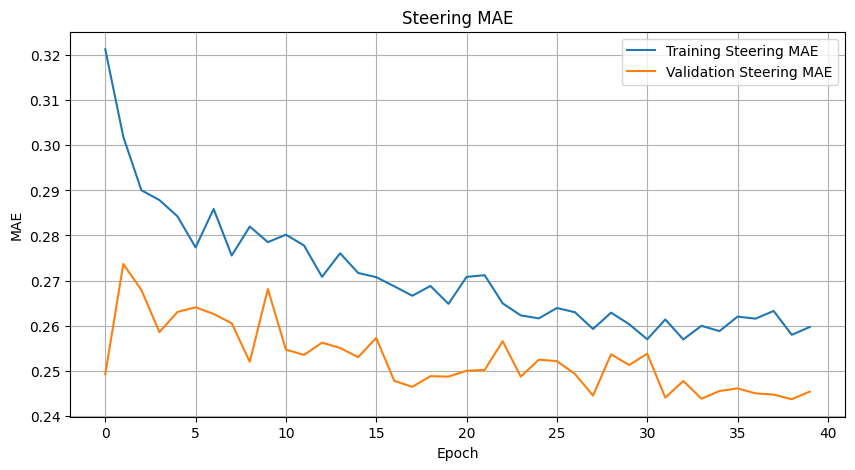

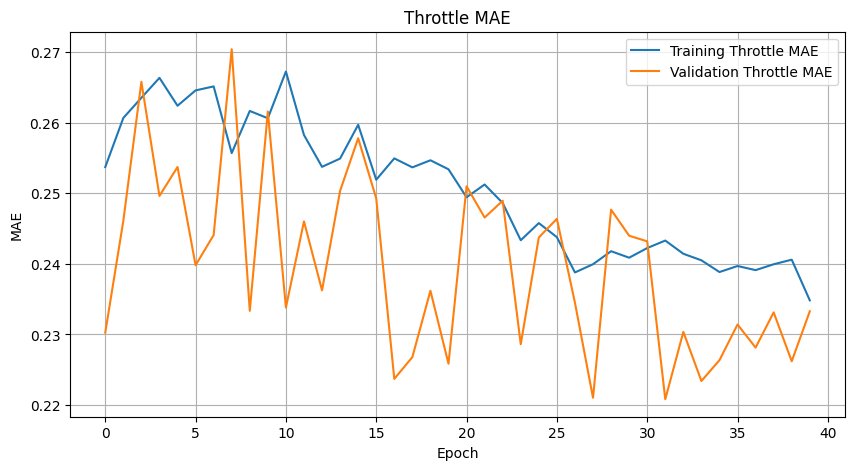

In [40]:
hist=pd.DataFrame(history.history); display(hist.tail())

# Steering MAE
plt.figure(figsize=(10,5))
plt.plot(hist["steering_mae"], label="Training Steering MAE")
plt.plot(hist["val_steering_mae"], label="Validation Steering MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.title("Steering MAE")
plt.legend()
plt.grid(True)
plt.show()


# Throttle MAE
plt.figure(figsize=(10,5))
plt.plot(hist["throttle_mae"], label="Training Throttle MAE")
plt.plot(hist["val_throttle_mae"], label="Validation Throttle MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.title("Throttle MAE")
plt.legend()
plt.grid(True)
plt.show()

In [37]:
model.save(os.path.join(MODEL_DIR,"neurodrive_final.keras"))
hist.to_csv(os.path.join(EXPERIMENT_DIR,"history.csv"),index=False)
print("Saved final model; best checkpoint:",os.path.join(MODEL_DIR,"neurodrive_best.keras"))

Saved final model; best checkpoint: C:\Users\user\Neuro Drive\models\neurodrive_best.keras


In [38]:
# Load test manifest
test_df = pd.read_csv(
    os.path.join(DATA_PROCESSED, "test_manifest.csv")
)

print("Test samples:", len(test_df))
display(test_df.head())

Test samples: 357


,center,left,right,steering,throttle
0,C:\Users\user\Neuro Drive\data\raw\IMG\center_...,C:\Users\user\Neuro Drive\data\raw\IMG\left_20...,C:\Users\user\Neuro Drive\data\raw\IMG\right_2...,0.0,0.415440
1,C:\Users\user\Neuro Drive\data\raw\IMG\center_...,C:\Users\user\Neuro Drive\data\raw\IMG\left_20...,C:\Users\user\Neuro Drive\data\raw\IMG\right_2...,0.0,0.000000
2,C:\Users\user\Neuro Drive\data\raw\IMG\center_...,C:\Users\user\Neuro Drive\data\raw\IMG\left_20...,C:\Users\user\Neuro Drive\data\raw\IMG\right_2...,0.0,0.090299
3,C:\Users\user\Neuro Drive\data\raw\IMG\center_...,C:\Users\user\Neuro Drive\data\raw\IMG\left_20...,C:\Users\user\Neuro Drive\data\raw\IMG\right_2...,-1.0,0.000000
4,C:\Users\user\Neuro Drive\data\raw\IMG\center_...,C:\Users\user\Neuro Drive\data\raw\IMG\left_20...,C:\Users\user\Neuro Drive\data\raw\IMG\right_2...,0.0,0.000000


In [41]:
X_test = []
y_test_steering = []
y_test_throttle = []

for _, row in test_df.iterrows():

    image = cv2.imread(row["center"])
    image = preprocess_image(image)

    X_test.append(image)
    y_test_steering.append(row["steering"])
    y_test_throttle.append(row["throttle"])

X_test = np.array(X_test, dtype=np.uint8)

y_test_steering = np.array(y_test_steering, dtype=np.float32)
y_test_throttle = np.array(y_test_throttle, dtype=np.float32)

y_test = {
    "steering": y_test_steering,
    "throttle": y_test_throttle
}

print("X_test:", X_test.shape)
print("Steering:", y_test_steering.shape)
print("Throttle:", y_test_throttle.shape)

X_test: (357, 66, 200, 3)
Steering: (357,)
Throttle: (357,)


In [43]:
best_model = keras.models.load_model(
    os.path.join(MODEL_DIR, "neurodrive_best.keras")
)

test_results = best_model.evaluate(
    X_test,
    y_test,
    return_dict=True,
    verbose=1
)

print("\n--- NeuroDrive V2 Test Results ---")

for metric, value in test_results.items():
    print(f"{metric}: {value:.6f}")

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.1857 - steering_loss: 0.0908 - steering_mae: 0.2386 - throttle_loss: 0.0868 - throttle_mae: 0.2380

--- NeuroDrive V2 Test Results ---
loss: 0.185663
steering_loss: 0.090835
steering_mae: 0.238591
throttle_loss: 0.086766
throttle_mae: 0.237968


12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step


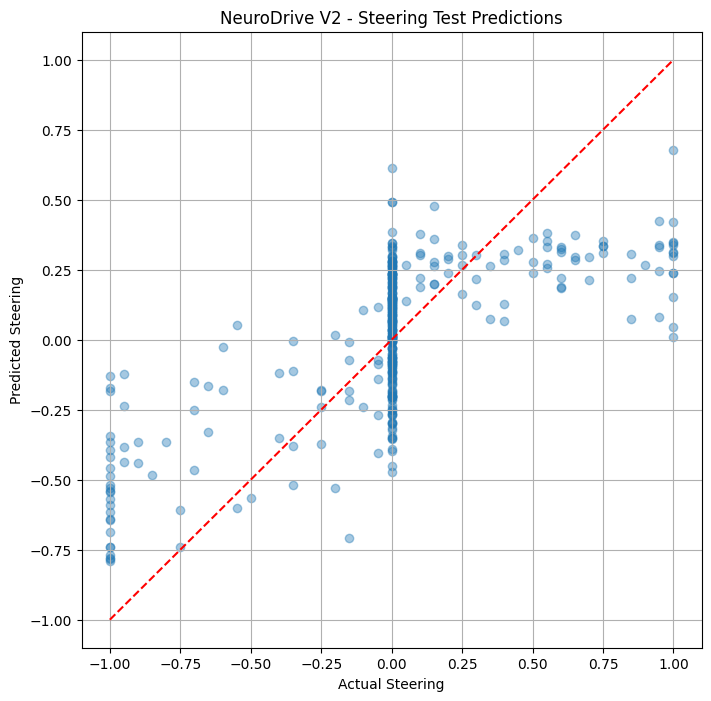

In [45]:
predictions = best_model.predict(X_test)

y_pred_steering = predictions["steering"].flatten()

plt.figure(figsize=(8, 8))

plt.scatter(
    y_test_steering,
    y_pred_steering,
    alpha=0.4
)

plt.plot([-1, 1], [-1, 1], "r--")

plt.xlabel("Actual Steering")
plt.ylabel("Predicted Steering")
plt.title("NeuroDrive V2 - Steering Test Predictions")

plt.grid(True)
plt.show()

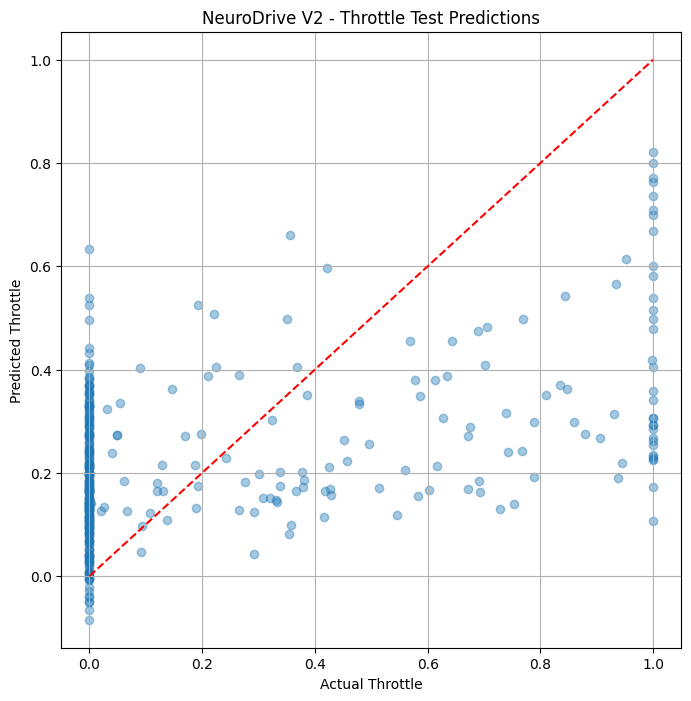

In [46]:
y_pred_throttle = predictions["throttle"].flatten()

plt.figure(figsize=(8, 8))

plt.scatter(
    y_test_throttle,
    y_pred_throttle,
    alpha=0.4
)

plt.plot([0, 1], [0, 1], "r--")

plt.xlabel("Actual Throttle")
plt.ylabel("Predicted Throttle")
plt.title("NeuroDrive V2 - Throttle Test Predictions")

plt.grid(True)
plt.show()

In [26]:
import shutil
from datetime import datetime

# Save V1 model
V1_MODEL_PATH = os.path.join(MODEL_DIR, "neurodrive_v2.keras")

shutil.copy2(
    os.path.join(MODEL_DIR, "neurodrive_best.keras"),
    V1_MODEL_PATH
)

# Save V1 training history
shutil.copy2(
    os.path.join(EXPERIMENT_DIR, "history.csv"),
    os.path.join(EXPERIMENT_DIR, "history_v1.csv")
)

print("V1 model saved:", V1_MODEL_PATH)

V1 model saved: C:\Users\user\Neuro Drive\models\neurodrive_v1.keras


In [29]:
import pandas as pd
import os


METRICS_PATH = os.path.join(EXPERIMENT_DIR, "model_metrics.csv")

# Latest epoch metrics
history_df = pd.DataFrame(history.history)

# Load best model
best_model = keras.models.load_model(
    os.path.join(MODEL_DIR, "neurodrive_v1.keras")
)

# Evaluate on test data
test_loss, test_mae = best_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

# Create V1 record
v1_metrics = {
    "version": "V1",
    "timestamp": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),

    "epochs_trained": len(history_df),

    "train_mse": history_df["loss"].iloc[-1],
    "train_mae": history_df["mae"].iloc[-1],

    "val_mse": history_df["val_loss"].iloc[-1],
    "val_mae": history_df["val_mae"].iloc[-1],

    "test_mse": test_loss,
    "test_mae": test_mae
}

# Append to CSV
metrics_df = pd.DataFrame([v1_metrics])

if os.path.exists(METRICS_PATH):
    metrics_df.to_csv(
        METRICS_PATH,
        mode="a",
        header=False,
        index=False
    )
else:
    metrics_df.to_csv(
        METRICS_PATH,
        index=False
    )

display(metrics_df)

print("Metrics saved:", METRICS_PATH)

,version,timestamp,epochs_trained,train_mse,train_mae,val_mse,val_mae,test_mse,test_mae
0,V1,2026-11-08 11:50:09,40,0.131509,0.277456,0.121039,0.264557,0.125329,0.269583


Metrics saved: C:\Users\user\Neuro Drive\experiments\training\model_metrics.csv
